In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import (
    StratifiedGroupKFold,
    GridSearchCV,
    cross_val_predict
)

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.pipeline import Pipeline as SkPipeline
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from sklearn.svm import SVC
from sklearn.base import clone

from sklearn.metrics import (
    classification_report,
    ConfusionMatrixDisplay,
    confusion_matrix,
    f1_score,
    make_scorer
)

from matplotlib.ticker import FuncFormatter

# Polski format liczb
def comma_formatter(x, pos):
    return f'{x:g}'.replace('.', ',')

formatter = FuncFormatter(comma_formatter)

In [3]:
ds1_df = pd.read_csv('../src/ds1_features.csv')
ds2_df = pd.read_csv('../src/ds2_features.csv')

CLASSES = ['N', 'S', 'V', 'F', 'Q']

metadata_columns = [
    'record_id',
    'annotation_sample',
    'type',
    'class',
    'anomaly',
    'lead'
]

feature_columns = [
    col for col in ds1_df.columns
    if col not in metadata_columns
]

X_train = ds1_df[feature_columns]
y_train = ds1_df['class']

X_test = ds2_df[feature_columns]
y_test = ds2_df['class']

In [4]:
groups = ds1_df['record_id'].replace({
    202: 201
})

cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [5]:
print('DS1:', X_train.shape)
print('DS2:', X_test.shape)
print('Liczba cech:', len(feature_columns))

class_distribution = pd.DataFrame({
    'DS1': y_train.value_counts(),
    'DS2': y_test.value_counts()
}).reindex(CLASSES, fill_value=0)

display(class_distribution)

assert X_train.shape[1] == 26
assert X_train.columns.equals(X_test.columns)
assert set(y_train.unique()) == set(CLASSES)
assert set(y_test.unique()) == set(CLASSES)

assert set(ds1_df['record_id']).isdisjoint(
    set(ds2_df['record_id'])
)

assert X_train.select_dtypes(exclude='number').empty
assert np.isfinite(X_train.dropna().to_numpy()).all()
assert np.isfinite(X_test.dropna().to_numpy()).all()

DS1: (57549, 26)
DS2: (51902, 26)
Liczba cech: 26


,DS1,DS2
class,,
N,48168,42425
S,999,1782
V,3813,3422
F,415,387
Q,4154,3886


In [11]:
svm_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('selector', SelectKBest(score_func=f_classif, k='all')),
    ('svm', SVC(
        kernel='rbf',
        C=1.0,
        gamma='scale',
        class_weight='balanced',
        cache_size=1000
    ))
])

1. test na jednym foldzie walidacyjnym. spodziewane wyniki słabe, bo podział powoduje, że czasami w treningu widoczne jest mało uderzeń klasy Q czy F

In [7]:
train_idx, val_idx = next(
    cv.split(X_train, y_train, groups=groups)
)

X_fold_train = X_train.iloc[train_idx]
X_fold_val = X_train.iloc[val_idx]

y_fold_train = y_train.iloc[train_idx]
y_fold_val = y_train.iloc[val_idx]

assert set(groups.iloc[train_idx]).isdisjoint(
    set(groups.iloc[val_idx])
)

print('Uczenie:', X_fold_train.shape)
print('Walidacja:', X_fold_val.shape)

Uczenie: (47345, 26)
Walidacja: (10204, 26)


In [8]:
svm_pipeline.fit(X_fold_train, y_fold_train)

y_fold_pred = svm_pipeline.predict(X_fold_val)

In [9]:
print(
    classification_report(
        y_fold_val,
        y_fold_pred,
        labels=CLASSES,
        zero_division=0
    )
)

fold_macro_f1 = f1_score(
    y_fold_val,
    y_fold_pred,
    labels=CLASSES,
    average='macro',
    zero_division=0
)

print(f'Macro F1: {fold_macro_f1:.4f}')

              precision    recall  f1-score   support

           N       0.98      0.81      0.89      9351
           S       0.08      0.24      0.12       186
           V       0.74      0.80      0.77       662
           F       0.00      0.00      0.00         3
           Q       0.00      0.00      0.00         2

    accuracy                           0.79     10204
   macro avg       0.36      0.37      0.36     10204
weighted avg       0.95      0.79      0.86     10204

Macro F1: 0.3562


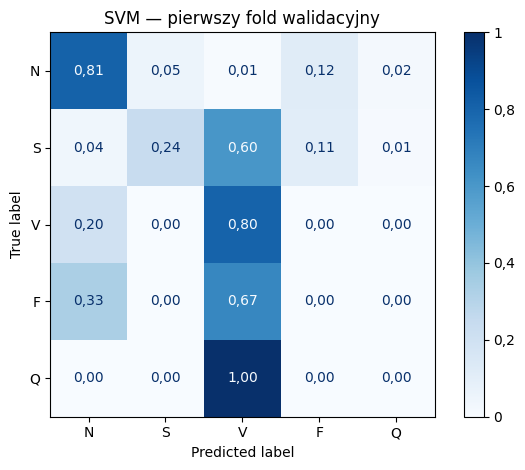

In [12]:
disp = ConfusionMatrixDisplay.from_predictions(
    y_fold_val,
    y_fold_pred,
    labels=CLASSES,
    display_labels=CLASSES,
    normalize='true',
    cmap='Blues',
    values_format='.2f'
)

# Przecinki w komórkach macierzy
for text in disp.text_.ravel():
    text.set_text(
        text.get_text().replace('.', ',')
    )

# Przecinki na pasku kolorów
disp.im_.colorbar.ax.yaxis.set_major_formatter(formatter)

plt.title('SVM — pierwszy fold walidacyjny')
plt.tight_layout()
plt.show()

2. dopasowanie modelu z gridsearchcv, 5 foldow, i selektor cech select k best

In [6]:
param_grid = {
    'selector__k': [10, 'all'],
    'svm__C': [0.1, 1],
    'svm__gamma': ['scale', 0.01]
}


macro_f1_scorer = make_scorer(
    f1_score,
    average='macro',
    labels=CLASSES,
    zero_division=0
)

In [18]:
grid_search = GridSearchCV(
    estimator=svm_pipeline,
    param_grid=param_grid,
    scoring=macro_f1_scorer,
    cv=cv,
    n_jobs=-1,
    verbose=2,
    refit=True,
    return_train_score=True
)

grid_search.fit(
    X_train,
    y_train,
    groups=groups
)

Fitting 5 folds for each of 8 candidates, totalling 40 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...'balanced'))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'selector__k': [10, 'all'], 'svm__C': [0.1, 1], 'svm__gamma': ['scale', 0.01]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",make_scorer(f...ro_division=0)
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedGro... shuffle=True)
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",2
,"return_train_score return_train_score: bool, default=FalseIf ``False``, the ``cv_results_`` attribute will not include trainingscores.Computing training scores is used to get insights on how differentparameter settings impact the overfitting/underfitting trade-off.However computing the scores on the training set can be computationallyexpensive and is not strictly required to select the parameters thatyield the best generalization performance... versionadded:: 0.19.. versionchanged:: 0.21 Default value was changed from ``True`` to ``False``",True
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` wil

In [19]:
results_df = pd.DataFrame(grid_search.cv_results_)

display(
    results_df[
        [
            'param_selector__k',
            'param_svm__C',
            'param_svm__gamma',
            'mean_test_score',
            'std_test_score',
            'rank_test_score'
        ]
    ].sort_values('rank_test_score')
)

print('Najlepsze parametry:')
print(grid_search.best_params_)

print(
    'Średni macro F1:',
    round(grid_search.best_score_, 4)
)

,param_selector__k,param_svm__C,param_svm__gamma,mean_test_score,std_test_score,rank_test_score
6,all,1.0,scale,0.370603,0.142857,1
5,all,0.1,0.01,0.363403,0.112213,2
7,all,1.0,0.01,0.363156,0.128293,3
3,10,1.0,0.01,0.359381,0.106906,4
0,10,0.1,scale,0.358753,0.122414,5
2,10,1.0,scale,0.356388,0.122274,6
1,10,0.1,0.01,0.351171,0.086764,7
4,all,0.1,scale,0.349250,0.134676,8


Najlepsze parametry:
{'selector__k': 'all', 'svm__C': 1, 'svm__gamma': 'scale'}
Średni macro F1: 0.3706


In [20]:
best_selector = grid_search.best_estimator_.named_steps['selector']

selected_features = X_train.columns[
    best_selector.get_support()
].tolist()

print('Wybrane cechy:')
print(selected_features)

Wybrane cechy:
['mean', 'std', 'min', 'max', 'peak_to_peak', 'median', 'iqr', 'skew', 'kurtosis', 'max_abs', 'rms', 'waveform_length', 'max_diff', 'qrs_abs_area', 'qrs_max_slope', 'amp_m80', 'amp_m40', 'amp_p0', 'amp_p40', 'amp_p80', 'qrs_min', 'qrs_max', 'qrs_peak_to_peak', 'rr_prev', 'rr_local_median', 'rr_prev_relative']


In [21]:
best_idx = grid_search.best_index_

fold_scores = pd.DataFrame({
    'fold': range(1, 6),
    'macro_f1': [
        grid_search.cv_results_[
            f'split{i}_test_score'
        ][best_idx]
        for i in range(5)
    ]
})

display(fold_scores.round(4))

,fold,macro_f1
0,1,0.3562
1,2,0.2319
2,3,0.3580
3,4,0.6388
4,5,0.2681


In [23]:
fold_results = []

for fold, (train_idx, val_idx) in enumerate(
    cv.split(X_train, y_train, groups=groups),
    start=1
):
    val_classes = y_train.iloc[val_idx]

    counts = (
        val_classes
        .value_counts()
        .reindex(CLASSES, fill_value=0)
    )

    fold_results.append({
        'fold': fold,
        'records': ds1_df.iloc[val_idx]['record_id'].nunique(),
        'samples': len(val_idx),
        **counts.to_dict()
    })

fold_summary = pd.DataFrame(fold_results)

display(fold_summary)

,fold,records,samples,N,S,V,F,Q
0,1,5,10204,9351,186,662,3,2
1,2,5,11904,9151,205,485,1,2062
2,3,5,11725,10347,389,982,3,4
3,4,5,11540,8724,107,595,30,2084
4,5,5,12176,10595,112,1089,378,2


In [24]:
fold_scores = fold_scores.merge(
    fold_summary,
    on='fold'
)

display(fold_scores.round(4))

,fold,macro_f1,records,samples,N,S,V,F,Q
0,1,0.3562,5,10204,9351,186,662,3,2
1,2,0.2319,5,11904,9151,205,485,1,2062
2,3,0.3580,5,11725,10347,389,982,3,4
3,4,0.6388,5,11540,8724,107,595,30,2084
4,5,0.2681,5,12176,10595,112,1089,378,2


In [26]:
best_pipeline = clone(grid_search.best_estimator_)

y_oof_pred = cross_val_predict(
    estimator=best_pipeline,
    X=X_train,
    y=y_train,
    groups=groups,
    cv=cv,
    method='predict',
    n_jobs=1
)

assert len(y_oof_pred) == len(y_train)

In [27]:
print(
    classification_report(
        y_train,
        y_oof_pred,
        labels=CLASSES,
        zero_division=0,
        digits=4
    )
)

oof_macro_f1 = f1_score(
    y_train,
    y_oof_pred,
    labels=CLASSES,
    average='macro',
    zero_division=0
)

print(f'OOF macro F1: {oof_macro_f1:.4f}')

              precision    recall  f1-score   support

           N     0.9351    0.7414    0.8271     48168
           S     0.0706    0.3463    0.1173       999
           V     0.3753    0.8408    0.5190      3813
           F     0.0084    0.0554    0.0145       415
           Q     0.7405    0.5655    0.6413      4154

    accuracy                         0.7235     57549
   macro avg     0.4260    0.5099    0.4238     57549
weighted avg     0.8623    0.7235    0.7751     57549

OOF macro F1: 0.4238


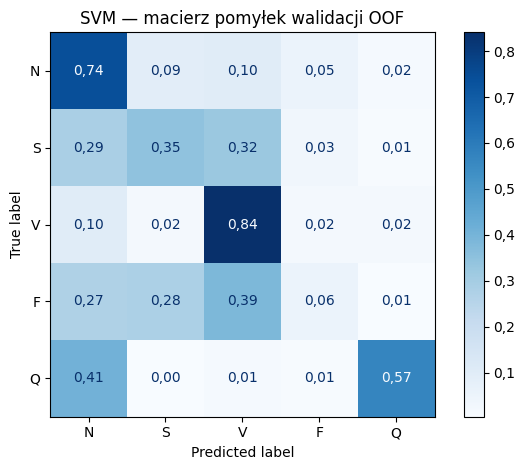

In [28]:
disp = ConfusionMatrixDisplay.from_predictions(
    y_train,
    y_oof_pred,
    labels=CLASSES,
    display_labels=CLASSES,
    normalize='true',
    cmap='Blues',
    values_format='.2f'
)

for label in disp.text_.ravel():
    label.set_text(
        label.get_text().replace('.', ',')
    )

disp.im_.colorbar.ax.yaxis.set_major_formatter(formatter)

plt.title('SVM — macierz pomyłek walidacji OOF')
plt.tight_layout()
plt.show()

In [29]:
param_grid_weights = {
    'selector__k': [10, 'all'],
    'svm__C': [1],
    'svm__gamma': ['scale'],
    'svm__class_weight': [None, 'balanced']
}

In [30]:
grid_weights = GridSearchCV(
    estimator=svm_pipeline,
    param_grid=param_grid_weights,
    scoring=macro_f1_scorer,
    cv=cv,
    n_jobs=1,
    verbose=2,
    refit=True,
    return_train_score=True
)

grid_weights.fit(
    X_train,
    y_train,
    groups=groups
)

Fitting 5 folds for each of 4 candidates, totalling 20 fits
[CV] END selector__k=10, svm__C=1, svm__class_weight=None, svm__gamma=scale; total time=   3.8s
[CV] END selector__k=10, svm__C=1, svm__class_weight=None, svm__gamma=scale; total time=   3.1s
[CV] END selector__k=10, svm__C=1, svm__class_weight=None, svm__gamma=scale; total time=   3.5s
[CV] END selector__k=10, svm__C=1, svm__class_weight=None, svm__gamma=scale; total time=   3.8s
[CV] END selector__k=10, svm__C=1, svm__class_weight=None, svm__gamma=scale; total time=   5.5s
[CV] END selector__k=10, svm__C=1, svm__class_weight=balanced, svm__gamma=scale; total time=  12.7s
[CV] END selector__k=10, svm__C=1, svm__class_weight=balanced, svm__gamma=scale; total time=  13.0s
[CV] END selector__k=10, svm__C=1, svm__class_weight=balanced, svm__gamma=scale; total time=  18.4s
[CV] END selector__k=10, svm__C=1, svm__class_weight=balanced, svm__gamma=scale; total time=  11.7s
[CV] END selector__k=10, svm__C=1, svm__class_weight=balance

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...'balanced'))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'selector__k': [10, 'all'], 'svm__C': [1], 'svm__class_weight': [None, 'balanced'], 'svm__gamma': ['scale']}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",make_scorer(f...ro_division=0)
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedGro... shuffle=True)
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",2
,"return_train_score return_train_score: bool, default=FalseIf ``False``, the ``cv_results_`` attribute will not include trainingscores.Computing training scores is used to get insights on how differentparameter settings impact the overfitting/underfitting trade-off.However computing the scores on the training set can be computationallyexpensive and is not strictly required to select the parameters thatyield the best generalization performance... versionadded:: 0.19.. versionchanged:: 0.21 Default value was changed from ``True`` to ``False``",True
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimato

In [31]:
weight_results = pd.DataFrame(grid_weights.cv_results_)

display(
    weight_results[
        [
            'param_selector__k',
            'param_svm__class_weight',
            'mean_test_score',
            'std_test_score',
            'rank_test_score'
        ]
    ].sort_values('rank_test_score')
)

,param_selector__k,param_svm__class_weight,mean_test_score,std_test_score,rank_test_score
3,all,balanced,0.370603,0.142857,1
0,10,NaN,0.357232,0.105927,2
1,10,balanced,0.356388,0.122274,3
2,all,NaN,0.349792,0.075365,4


In [7]:
param_grid_extended = {
    'selector__k': ['all'],
    'svm__class_weight': ['balanced'],
    'svm__C': [0.5, 1, 5, 10],
    'svm__gamma': [0.001, 0.01, 'scale', 0.1]
}

In [ ]:
grid_extended = GridSearchCV(
    estimator=svm_pipeline,
    param_grid=param_grid_extended,
    scoring=macro_f1_scorer,
    cv=cv,
    n_jobs=1,
    verbose=2,
    refit=True,
    return_train_score=True
)

grid_extended.fit(
    X_train,
    y_train,
    groups=groups
)

Fitting 5 folds for each of 16 candidates, totalling 80 fits
[CV] END selector__k=all, svm__C=0.5, svm__class_weight=balanced, svm__gamma=0.001; total time= 4.1min
[CV] END selector__k=all, svm__C=0.5, svm__class_weight=balanced, svm__gamma=0.001; total time= 2.7min
[CV] END selector__k=all, svm__C=0.5, svm__class_weight=balanced, svm__gamma=0.001; total time= 2.9min
[CV] END selector__k=all, svm__C=0.5, svm__class_weight=balanced, svm__gamma=0.001; total time= 2.4min
[CV] END selector__k=all, svm__C=0.5, svm__class_weight=balanced, svm__gamma=0.001; total time= 3.1min
[CV] END selector__k=all, svm__C=0.5, svm__class_weight=balanced, svm__gamma=0.01; total time= 1.8min
[CV] END selector__k=all, svm__C=0.5, svm__class_weight=balanced, svm__gamma=0.01; total time= 1.3min
[CV] END selector__k=all, svm__C=0.5, svm__class_weight=balanced, svm__gamma=0.01; total time=  58.5s
[CV] END selector__k=all, svm__C=0.5, svm__class_weight=balanced, svm__gamma=0.01; total time=  58.8s
[CV] END selecto

In [ ]:
grid_extended_results = pd.DataFrame(grid_extended.cv_results_)

display(
    grid_extended_results[
        [
            'param_selector__k',
            'param_svm__class_weight',
            'mean_test_score',
            'std_test_score',
            'rank_test_score'
        ]
    ].sort_values('rank_test_score')
)

NameError: name 'grid_extended' is not defined

In [ ]:
print('Najlepsze parametry:')
print(grid_extended.best_params_)

print('Najlepszy średni macro F1:')
print(grid_extended.best_score_)

Najlepsze parametry:


NameError: name 'grid_extended' is not defined

In [ ]:
cv_splits = list(
    cv.split(X_train, y_train, groups=groups)
)

assert len(cv_splits) == 5

In [ ]:
svm_baseline = SkPipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('selector', SelectKBest(
        score_func=f_classif,
        k='all'
    )),
    ('svm', SVC(
        kernel='rbf',
        cache_size=1000
    ))
])

In [ ]:
baseline_grid = {
    'selector__k': [15, 'all'],
    'svm__C': [0.5, 1, 5, 10],
    'svm__gamma': ['scale', 0.01],
    'svm__class_weight': [None, 'balanced']
}

In [ ]:
grid_baseline = GridSearchCV(
    estimator=svm_baseline,
    param_grid=baseline_grid,
    scoring='f1_macro',
    cv=cv_splits,
    n_jobs=1,
    verbose=2,
    refit=False,
    return_train_score=False,
    error_score='raise'
)

grid_baseline.fit(X_train, y_train)

In [ ]:
baseline_results = pd.DataFrame(grid_baseline.cv_results_)

baseline_results.to_csv(
    '../src/svm_baseline_cv_results.csv',
    index=False
)

display(
    baseline_results[[
        'param_selector__k',
        'param_svm__C',
        'param_svm__gamma',
        'param_svm__class_weight',
        'mean_test_score',
        'std_test_score',
        'rank_test_score'
    ]].sort_values('rank_test_score').head(10)
)

print('Najlepsze parametry:', grid_baseline.best_params_)
print('Najlepszy macro F1:', grid_baseline.best_score_)

In [ ]:
def smote_strategy(y):

    counts = pd.Series(y).value_counts()

    strategy = {}

    for cls in ['S', 'V', 'F', 'Q']:

        current = int(counts.get(cls, 0))

        if current < 2:
            continue

        target = min(
            current * 3,
            3000
        )

        if target > current:
            strategy[cls] = target

    return strategy

In [ ]:
svm_smote = ImbPipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('selector', SelectKBest(
        score_func=f_classif,
        k='all'
    )),
    ('smote', SMOTE(
        sampling_strategy=smote_strategy,
        random_state=42
    )),
    ('svm', SVC(
        kernel='rbf',
        class_weight=None,
        cache_size=1000
    ))
])

In [ ]:
smote_grid = {
    'selector__k': [15, 'all'],
    'smote__k_neighbors': [3, 5],
    'svm__C': [1, 5],
    'svm__gamma': ['scale', 0.01]
}

In [ ]:
grid_smote = GridSearchCV(
    estimator=svm_smote,
    param_grid=smote_grid,
    scoring='f1_macro',
    cv=cv_splits,
    n_jobs=1,
    verbose=2,
    refit=False,
    return_train_score=False,
    error_score='raise'
)

grid_smote.fit(X_train, y_train)

In [ ]:
smote_results = pd.DataFrame(grid_smote.cv_results_)

smote_results.to_csv(
    '../src/svm_smote_cv_results.csv',
    index=False
)

display(
    smote_results[[
        'param_selector__k',
        'param_smote__k_neighbors',
        'param_svm__C',
        'param_svm__gamma',
        'mean_test_score',
        'std_test_score',
        'rank_test_score'
    ]].sort_values('rank_test_score').head(10)
)

print('Najlepsze parametry:', grid_smote.best_params_)
print('Najlepszy macro F1:', grid_smote.best_score_)

In [ ]:
comparison = pd.DataFrame({
    'Model': ['SVM', 'SVM + SMOTE'],
    'Macro F1': [
        grid_baseline.best_score_,
        grid_smote.best_score_
    ],
    'Std F1': [
        grid_baseline.cv_results_['std_test_score'][
            grid_baseline.best_index_
        ],
        grid_smote.cv_results_['std_test_score'][
            grid_smote.best_index_
        ]
    ]
})

display(comparison.round(4))

In [ ]:
fold_comparison = pd.DataFrame({
    'fold': range(1, 6),
    'SVM': [
        grid_baseline.cv_results_[f'split{i}_test_score'][
            grid_baseline.best_index_
        ]
        for i in range(5)
    ],
    'SVM + SMOTE': [
        grid_smote.cv_results_[f'split{i}_test_score'][
            grid_smote.best_index_
        ]
        for i in range(5)
    ]
})

display(fold_comparison.round(4))